# Lab 6 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It imports your finished functions from `../src/lab06.py` and plots their output.
One cell (the forecast reconstruction) asks you to re-run your own Task 4 steps to get
the actual predictions — if a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the reconstruction cell and the three plot cells, then **export each
figure and paste it into `report.pdf`** (right-click → Save image as…, or
`plt.savefig('fig1.png', dpi=150)`). Report figures 1–3 are required by the report template.


In [1]:
from pathlib import Path
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab06

series = lab06.load_data('../data/cafe_daily.csv')
results = lab06.run_experiment(series)
results

{'n_train': 739,
 'n_val': 150,
 'n_test': 150,
 'scale_mean': 170.4754,
 'scale_std': 25.5496,
 'naive_scale': 16.2314,
 'persistence': {'mae': 15.5067, 'rmse': 20.0934, 'mase': 0.9554},
 'rnn': {'mae': 9.4045, 'rmse': 11.8727, 'mase': 0.5794}}

In [2]:
# ============ TODO (forecast reconstruction) ============
# Same steps as run_experiment (docstring steps 1-8), so the forecasts below are
# exactly the ones behind `results`.
lab06.set_seed()
train_idx, val_idx, test_idx = lab06.temporal_split(len(series))
mean = np.mean(series[train_idx])
std = np.std(series[train_idx])
X_train, y_train = lab06.make_windows((series[train_idx] - mean) / std, lab06.WINDOW, lab06.HORIZON)
X_val, y_val = lab06.make_windows((series[val_idx] - mean) / std, lab06.WINDOW, lab06.HORIZON)
X_test, y_test = lab06.make_windows((series[test_idx] - mean) / std, lab06.WINDOW, lab06.HORIZON)
model, history = lab06.train_model(lab06.build_rnn(), X_train, y_train, X_val, y_val)

y_true = y_test * std + mean
pred_rnn = lab06.predict(model, X_test) * std + mean
pred_persistence = X_test[:, -1] * std + mean

# position in the original series of each test target, for the x axis
test_days = test_idx[lab06.WINDOW + lab06.HORIZON - 1:]

# sanity check: the reconstruction reproduces run_experiment's numbers
naive_scale = np.mean(np.abs(np.diff(series[train_idx])))
assert lab06.compute_metrics(y_true, pred_rnn, naive_scale) == results["rnn"]
assert lab06.compute_metrics(y_true, pred_persistence, naive_scale) == results["persistence"]
print("best epoch:", history["best_epoch"], "| test windows:", len(y_true))
# ========================================================


best epoch: 81 | test windows: 150


## Report figure 1 — the series and the chronological split

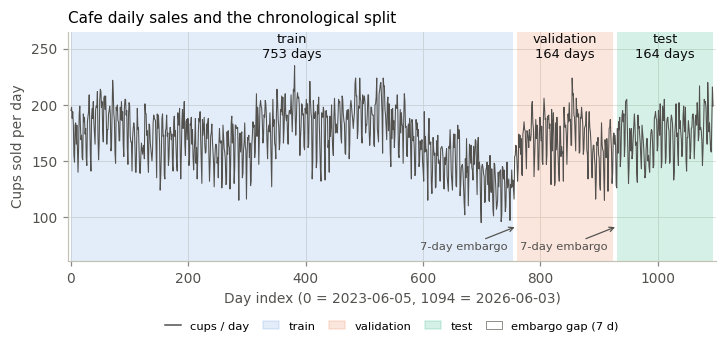

In [3]:
# ============ TODO (Report figure 1) ============
import pandas as pd
from matplotlib.patches import Patch

FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
BLUE, ORANGE, AQUA, WEEKEND = "#2a78d6", "#eb6834", "#1baf7a", "#ecebe6"
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

dates = pd.to_datetime(pd.read_csv("../data/cafe_daily.csv").sort_values("date")["date"]).reset_index(drop=True)
segments = [("train", train_idx, BLUE, 0.13), ("validation", val_idx, ORANGE, 0.16), ("test", test_idx, AQUA, 0.18)]

fig, ax = plt.subplots(figsize=(7.6, 2.7))
for name, idx, color, alpha in segments:
    ax.axvspan(idx[0] - 0.5, idx[-1] + 0.5, color=color, alpha=alpha, lw=0)
    ax.text((idx[0] + idx[-1]) / 2, series.max() + 4, f"{name}\n{len(idx)} days",
            ha="center", va="bottom", color=INK, fontsize=8.5)
ax.plot(np.arange(len(series)), series, color=INK2, lw=0.7)
for a, b in [(train_idx[-1], val_idx[0]), (val_idx[-1], test_idx[0])]:
    ax.annotate(f"{lab06.GAP}-day embargo", xy=((a + b) / 2, series.min() - 4), xytext=((a + b) / 2 - 12, series.min() - 22),
                fontsize=7.5, color=INK2, ha="right", va="center",
                arrowprops=dict(arrowstyle="->", color=INK2, lw=0.8, shrinkA=1, shrinkB=0))
ax.set_ylim(series.min() - 34, series.max() + 30)
ax.set_xlim(-5, len(series) + 4)
ax.set_xlabel(f"Day index (0 = {dates[0].date()}, {len(series) - 1} = {dates.iloc[-1].date()})")
ax.set_ylabel("Cups sold per day")
ax.set_title("Cafe daily sales and the chronological split")
handles = [plt.Line2D([], [], color=INK2, lw=1, label="cups / day")] + [
    Patch(color=c, alpha=a, label=n) for n, _, c, a in segments] + [
    Patch(facecolor="white", edgecolor=MUTED, lw=0.6, label=f"embargo gap ({lab06.GAP} d)")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=5, fontsize=7.5,
          handlelength=1.4, columnspacing=1.2)
fig.savefig(FIG_DIR / "fig1_split.png")
plt.show()
# ===============================================


## Report figure 2 — forecasts on the test segment

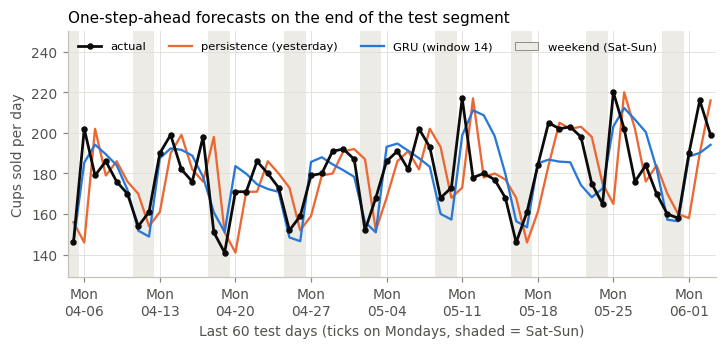

,persistence,rnn
weekday,,
Mon,34.2,8.9
Tue,10.8,9.1
Wed,8.6,11.5
Thu,11.9,11.5
Fri,11.5,9.1
Sat,23.3,8.2
Sun,7.9,7.5


In [4]:
# ============ TODO (Report figure 2) ============
last = slice(-60, None)
days, truth = test_days[last], y_true[last]
weekday = dates[days].dt.dayofweek.to_numpy()          # 0 = Mon ... 5 = Sat, 6 = Sun

fig, ax = plt.subplots(figsize=(7.6, 2.9))
for d in days[weekday >= 5]:
    ax.axvspan(d - 0.5, d + 0.5, color=WEEKEND, lw=0, zorder=0)
ax.plot(days, truth, color=INK, lw=1.8, marker="o", ms=3.2, label="actual", zorder=3)
ax.plot(days, pred_persistence[last], color=ORANGE, lw=1.5, label="persistence (yesterday)", zorder=2)
ax.plot(days, pred_rnn[last], color=BLUE, lw=1.5, label="GRU (window 14)", zorder=2)

mondays = days[weekday == 0]
ax.set_xticks(mondays)
ax.set_xticklabels([f"Mon\n{dates[d]:%m-%d}" for d in mondays])
ax.set_xlim(days[0] - 0.5, days[-1] + 0.5)
ax.set_xlabel("Last 60 test days (ticks on Mondays, shaded = Sat-Sun)")
ax.set_ylabel("Cups sold per day")
ax.set_title("One-step-ahead forecasts on the end of the test segment")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(facecolor=WEEKEND, edgecolor=MUTED, lw=0.6, label="weekend (Sat-Sun)")],
          loc="upper left", ncol=4, fontsize=7.5)
ax.set_ylim(truth.min() - 12, truth.max() + 30)
fig.savefig(FIG_DIR / "fig2_forecasts.png")
plt.show()

# where is persistence furthest from the truth?
err = pd.DataFrame({"weekday": dates[test_days].dt.day_name().str[:3].to_numpy(),
                    "persistence": np.abs(y_true - pred_persistence), "rnn": np.abs(y_true - pred_rnn)})
err.groupby("weekday")[["persistence", "rnn"]].mean().reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).round(1)
# ===============================================


## Report figure 3 — error comparison

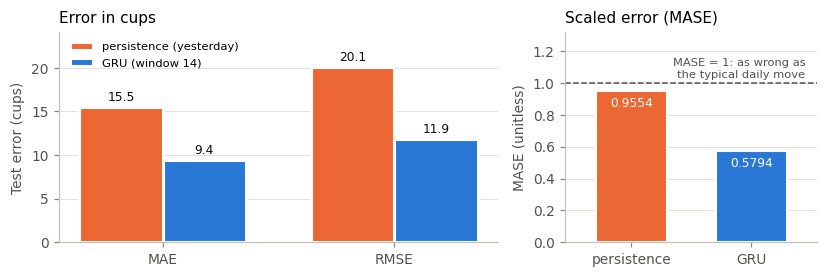

In [5]:
# ============ TODO (Report figure 3) ============
models = [("persistence", "persistence (yesterday)", ORANGE), ("rnn", "GRU (window 14)", BLUE)]
fig, (ax_c, ax_m) = plt.subplots(1, 2, figsize=(7.6, 2.6), gridspec_kw={"width_ratios": [2, 1.15]})

# left: errors in cups (MAE, RMSE); right: MASE, which has no unit -- separate axes, never one shared scale
width = 0.36
for j, (key, label, color) in enumerate(models):
    vals = [results[key]["mae"], results[key]["rmse"]]
    bars = ax_c.bar(np.arange(2) + (j - 0.5) * width, vals, width, color=color, edgecolor="white", lw=2, label=label)
    ax_c.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color=INK)
    bar = ax_m.bar(j, results[key]["mase"], 0.6, color=color, edgecolor="white", lw=2)
    ax_m.bar_label(bar, fmt="%.4f", padding=-13, fontsize=8, color="white")   # inside the bar, clear of the line at 1
ax_c.set_xticks(np.arange(2), ["MAE", "RMSE"])
ax_c.set_ylabel("Test error (cups)")
ax_c.set_ylim(0, max(results["persistence"]["rmse"], results["rnn"]["rmse"]) * 1.2)
ax_c.set_title("Error in cups")
ax_c.grid(axis="x", visible=False)

ax_m.axhline(1.0, color=INK2, lw=1, ls="--")
ax_m.text(1.45, 1.02, "MASE = 1: as wrong as\nthe typical daily move", ha="right", va="bottom", fontsize=7.5, color=INK2)
ax_m.set_xticks([0, 1], ["persistence", "GRU"])
ax_m.set_xlim(-0.55, 1.55)
ax_m.set_ylim(0, 1.32)
ax_m.set_ylabel("MASE (unitless)")
ax_m.set_title("Scaled error (MASE)")
ax_m.grid(axis="x", visible=False)

ax_c.legend(loc="upper left", fontsize=7.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_metrics.png")
plt.show()
# ===============================================
